# 18 — The v2 verdict: criteria C6–C12 scored as registered

Notebook 11's first cell wrote criteria C6–C12 before any v2 number existed (decision #52). This notebook scores them from the results files of notebooks 11, 12, 14 and 16, line by line, with the same rule as notebook 08: a "beat" passes only when the 95% paired interval lies entirely on the better side. It also shows the v1 verdict beside the v2 one, reruns nothing, and adds the Track B calibration plot the v1 report lacked. Failures are reported, not removed.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria_v2.csv`, `results/success_criteria_v2_registered.json` | notebook 11 — the registered lines |
| in | `results/metrics_v2.csv`, `results/level_repair_metrics.csv`, `results/landmark_metrics.csv`, `results/landmark_checks.csv`, `results/backtest_books.csv`, `results/book_coverage.csv` | notebooks 11/12/14/16 |
| in | `results/success_criteria.csv`, `results/trackB_calibration.csv` | notebooks 08/07 — the v1 verdict and Track B's calibration |
| out | `results/success_criteria_v2_scored.csv` | one row per registered line with PASS/FAIL |
| out | `results/verdict_summary.csv` | v1 and v2 counts side by side |
| out | `figures/18_evaluate_v2/*` | the scored criteria and the Track B calibration plot |
| out | `results/evaluate_v2_checks.csv` | this notebook's checks |
| in | `results/cif_horizons.csv`, `archetype_profiles.csv`, `metrics.csv`, `drift_by_cohort.csv`, `drivers_5yr.csv`, `hazards_by_queue_year.csv`, `npv_table.csv`, `portfolio_review_summary.csv`, `policy_comparison.csv`, `recommended_books.csv`, `timing_error.csv` | the decision board (section 4) |
| out | `results/decision_board.csv`, `figures/D0_decision_board.*` … `D6_policies.*` | seven images, one per decision |

## Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "18_evaluate_v2"
R = paths.RESULTS
registered = json.loads((R / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
criteria = pd.read_csv(R / "success_criteria_v2.csv")
print(f"registered {registered['decided']}: {len(criteria)} lines; bootstrap {registered['n_boot']} resamples, level {registered['level']}")


def save(fig, name, caption):
    """Save a figure of this notebook under figures/18_evaluate_v2/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

registered 2026-10-06: 8 lines; bootstrap 200 resamples, level 0.95


## 1. Scoring each line

The rules, as registered: C6 and C8–C10 are paired "beat" lines (interval entirely on the better side); C7 asks for a slope interval within 0.8–1.2 *and* an intercept interval covering 0 after the level repair; C11 asks the simulated 5–95% band to cover the realised MW; C12 holds when the dated-feature test passes and the landmark AUC stays below the ablation's.

In [2]:
m11 = pd.read_csv(R / "metrics_v2.csv")
m12 = pd.read_csv(R / "level_repair_metrics.csv")
m14 = pd.read_csv(R / "landmark_metrics.csv")
c14 = pd.read_csv(R / "landmark_checks.csv")
m16 = pd.read_csv(R / "backtest_books.csv")
cov = pd.read_csv(R / "book_coverage.csv")
chosen = json.loads((R / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
rows = []

# C6: ≥ 20 MW, v2 model vs fair baseline, Uno's C and Brier at 3 and 5 years
for metric in ["uno_c", "brier"]:
    for h in [3, 5]:
        r = m11[(m11["cohort"] == "≥ 20 MW") & (m11["reference"] == "fair_baseline") & (m11["model"] == chosen)
                & (m11["metric"] == metric) & (m11["horizon"] == h)].iloc[0]
        rows.append({"id": "C6", "line": f"≥ 20 MW: v2 vs fair baseline, {metric} at {h} years", "estimate": r["estimate"],
                     "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                     "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C7: 2018–2019 ≥ 20 MW after the level repair: slope within 0.8–1.2 and intercept covering 0, at 3 and 5
for h in [3, 5]:
    part = m12[(m12["cohort"] == "2018–2019, ≥ 20 MW") & (m12["model"] == "v2 recalibrated") & (m12["horizon"] == h)].set_index("metric")
    slope_ok = 0.8 <= part.loc["slope", "low"] and part.loc["slope", "high"] <= 1.2
    int_ok = part.loc["intercept", "low"] <= 0 <= part.loc["intercept", "high"]
    rows.append({"id": "C7", "line": f"2018–2019 ≥ 20 MW, level repaired: slope and intercept at {h} years",
                 "estimate": part.loc["slope", "estimate"], "benchmark": part.loc["intercept", "estimate"],
                 "diff": np.nan, "diff_low": part.loc["intercept", "low"], "diff_high": part.loc["intercept", "high"],
                 "rule": "slope interval within 0.8–1.2 and intercept interval covering 0", "result": "PASS" if slope_ok and int_ok else "FAIL"})
# C8: landmark +24 months and agreement vs entry model, Uno's C 3 years after
for lm, label in [("2", "+24 months"), ("agreement", "agreement executed")]:
    r = m14[(m14["landmark"].astype(str) == lm) & (m14["reference"] == "entry model") & (m14["model"] == "both updated")
            & (m14["metric"] == "uno_c") & (m14["horizon_after"] == 3)].iloc[0]
    rows.append({"id": "C8", "line": f"landmark {label}: both updated vs entry model, Uno's C 3 years after", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                 "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C9, C10: backtest, model book vs fair-baseline book
for cid, metric, label in [("C9", "realised_mw_5yr", "realised MW online within 5 years"), ("C10", "realised_value_$M", "realised value, base case")]:
    r = m16[(m16["chooser"] == "v2 model, level repaired") & (m16["metric"] == metric)].iloc[0]
    rows.append({"id": cid, "line": f"backtest: model book vs fair-baseline book, {label}", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff_vs_fair_baseline"], "diff": r["diff_vs_fair_baseline"], "diff_low": r["diff_low"],
                 "diff_high": r["diff_high"], "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats_fair_baseline"]) else "FAIL"})
# C11: coverage
r = cov.iloc[0]
rows.append({"id": "C11", "line": "simulated 5–95% band covers the realised MW of the model's book", "estimate": r["realised_mw_5yr"],
             "benchmark": r["expected_mw_5yr"], "diff": np.nan, "diff_low": r["band_low"], "diff_high": r["band_high"],
             "rule": "realised inside the band", "result": "PASS" if bool(r["covered"]) else "FAIL"})
# C12: leakage guard
guard = c14[c14["check"].str.startswith("leakage guard")]
rows.append({"id": "C12", "line": "leakage guard: dated features (test) and landmark AUC below the ablation's", "estimate": np.nan, "benchmark": np.nan,
             "diff": np.nan, "diff_low": np.nan, "diff_high": np.nan, "rule": "both hold", "result": "PASS" if bool(guard["pass"].all()) else "FAIL"})
scored = pd.DataFrame(rows)
scored.to_csv(R / "success_criteria_v2_scored.csv", index=False)
n_pass = int((scored["result"] == "PASS").sum())
print(f"{n_pass} of {len(scored)} registered v2 lines pass")
scored.round(3)

3 of 12 registered v2 lines pass


,id,line,estimate,benchmark,diff,diff_low,diff_high,rule,result
0,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 3 years",0.779,0.783,-0.004,-0.044,0.046,paired interval on the better side,FAIL
1,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 5 years",0.734,0.752,-0.018,-0.051,0.015,paired interval on the better side,FAIL
2,C6,"≥ 20 MW: v2 vs fair baseline, brier at 3 years",0.022,0.023,-0.001,-0.003,0.001,paired interval on the better side,FAIL
3,C6,"≥ 20 MW: v2 vs fair baseline, brier at 5 years",0.064,0.064,0.000,-0.002,0.003,paired interval on the better side,FAIL
4,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 3 years",1.088,-0.735,NaN,-1.168,-0.406,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
5,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 5 years",1.183,-0.474,NaN,-0.699,-0.269,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
6,C8,"landmark +24 months: both updated vs entry model, Uno's C 3 years after",0.788,0.687,0.101,0.062,0.136,paired interval on the better side,PASS
7,C8,"landmark agreement executed: both updated vs entry model, Uno's C 3 years after",0.598,0.593,0.004,-0.016,0.028,paired interval on the better side,FAIL
8,C9,"backtest: model book vs fair-baseline book, realised MW online within 5 years",1035.000,1035.000,0.000,-17.733,449.755,paired interval on the better side,FAIL
9,C10,"backtest: model book vs fair-baseline book, realised value, base case",1463.216,1463.227,-0.011,-53.834,576.898,paired interval on the better side,FAIL


**Reading this.** Three of twelve lines pass, and the pattern is the finding. At entry, for requests of 20 MW and more, the model and the fair baseline are indistinguishable: Uno's C 0.779 against 0.783 and 0.734 against 0.752, Brier scores equal to three decimals, every interval straddling zero (C6: 0 of 4). The level repair leaves the 2018–2019 intercept at −0.74 and −0.47 with intervals well below zero (C7: 0 of 2). Two years into the queue, the agreement flag lifts Uno's C by +0.101 [+0.062, +0.136] (C8 passes at +24 months) but not at the agreement itself (+0.004). The registered backtest is a tie: the model's book and the fair baseline's book realised the same 1,035 MW, because an expected-value objective under a sunk-cost budget makes every chooser buy the same large requests (C9, C10 fail; notebook 16's exploratory count-limited book is reported there, not here). The simulated band covers the realised MW (C11) and the leakage guard holds (C12). Read together: machine learning adds nothing at entry for utility-scale requests, adds a measurable ranking gain at the milestones, and no entry-time model here is calibrated to the post-2017 level.

## 2. The two verdicts side by side

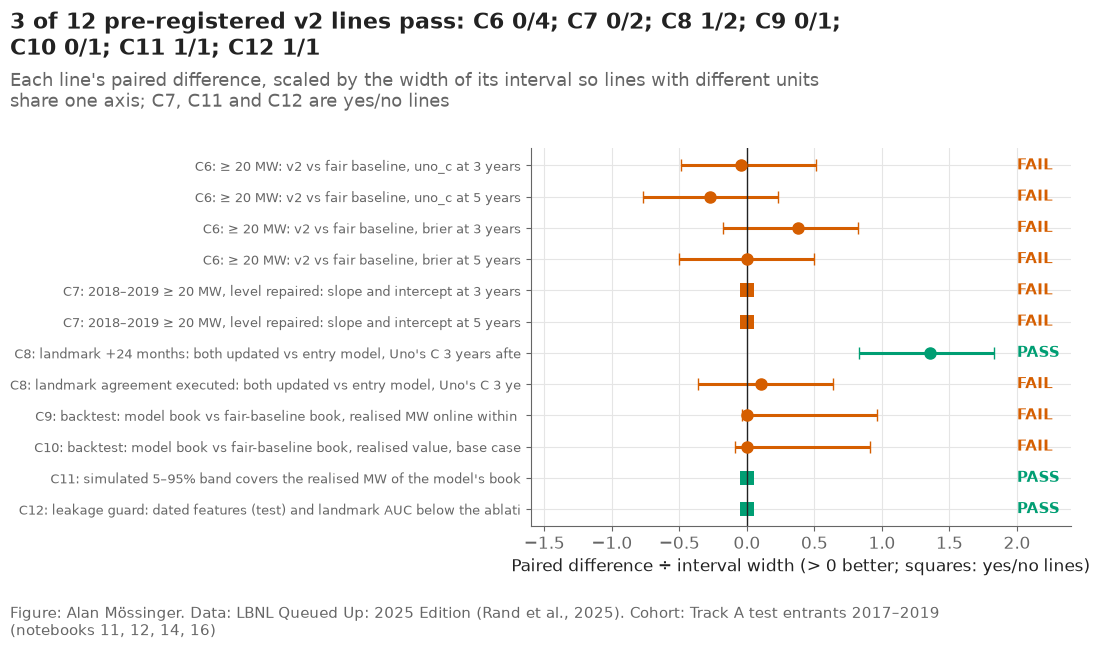

,version,lines,pass,what passes,what fails
0,"v1 (notebook 08, decision #5)",12,8,ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift...,ranking at 7 years; calibration at 3 and 5 years
1,"v2 (this notebook, decision #52)",12,3,C8; C11; C12,C6; C7; C8; C9; C10


In [3]:
v1 = pd.read_csv(R / "success_criteria.csv")
summary = pd.DataFrame([
    {"version": "v1 (notebook 08, decision #5)", "lines": len(v1), "pass": int((v1["result"] == "PASS").sum()),
     "what passes": "ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift; Track B",
     "what fails": "ranking at 7 years; calibration at 3 and 5 years"},
    {"version": "v2 (this notebook, decision #52)", "lines": len(scored), "pass": n_pass,
     "what passes": "; ".join(scored.loc[scored["result"] == "PASS", "id"].unique()),
     "what fails": "; ".join(scored.loc[scored["result"] == "FAIL", "id"].unique())},
])
summary.to_csv(R / "verdict_summary.csv", index=False)
by_id = scored.groupby("id")["result"].apply(lambda s: f"{int((s == 'PASS').sum())}/{len(s)}")

fig, ax = plt.subplots(figsize=(11, 6.5))
order = ["C6", "C7", "C8", "C9", "C10", "C11", "C12"]
y = 0
ticks, labels = [], []
for cid in order:
    part = scored[scored["id"] == cid]
    for _, r in part.iterrows():
        color = "#009E73" if r["result"] == "PASS" else "#D55E00"
        if pd.notna(r["diff"]):
            est, lo, hi = r["diff"], r["diff_low"], r["diff_high"]
            if "brier" in r["line"] or "Brier" in r["line"]:
                est, lo, hi = -est, -hi, -lo
            scale = abs(est) if abs(est) > 0 else 1.0
            ax.errorbar(est / max(abs(hi - lo), 1e-9), y, xerr=[[(est - lo) / max(abs(hi - lo), 1e-9)], [(hi - est) / max(abs(hi - lo), 1e-9)]],
                        fmt="o", color=color, capsize=4, markersize=8)
        else:
            ax.scatter(0, y, marker="s", color=color, s=90)
        ax.annotate(r["result"], (2.0, y), ha="left", va="center", color=color, fontweight="bold", fontsize=11)
        ticks.append(y); labels.append(f"{cid}: {r['line'][:70]}")
        y += 1
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(ticks, labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-1.6, 2.4)
ax.set_xlabel("Paired difference ÷ interval width (> 0 better; squares: yes/no lines)", fontsize=12)
plots.finish(fig,
             f"{n_pass} of {len(scored)} pre-registered v2 lines pass: " + "; ".join(f"{cid} {by_id[cid]}" for cid in order),
             "Each line's paired difference, scaled by the width of its interval so lines with different units share one axis; "
             "C7, C11 and C12 are yes/no lines",
             "Track A test entrants 2017–2019 (notebooks 11, 12, 14, 16)")
save(fig, "18_01_v2_criteria", "The pre-registered v2 criteria scored, with PASS/FAIL per line.")
plt.show()
summary

**Reading this.** The two verdicts measure different things. The v1 lines compared the model with a baseline that ignored size and passed 8 of 12; the v2 lines compare it with a baseline that knows size, at utility scale, after the level drifted, and in a decision frame, and pass 3 of 12. The v1 result stands as registered; the v2 result says what it was worth. Both are reported, neither is softened.

## 3. Track B's calibration (the plot the v1 report lacked)

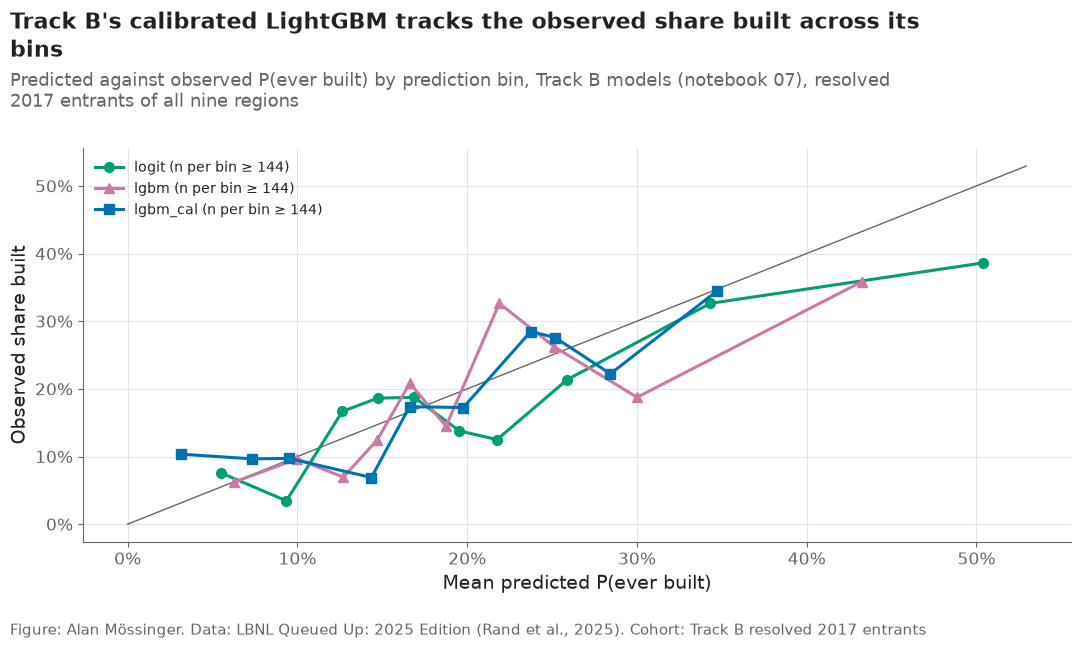

In [4]:
cal = pd.read_csv(R / "trackB_calibration.csv")
fig, ax = plt.subplots(figsize=(11, 6.5))
top = max(cal["predicted"].max(), cal["observed"].max()) * 1.05
ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
for model, color, marker in [("logit", "#009E73", "o"), ("lgbm", "#CC79A7", "^"), ("lgbm_cal", "#0072B2", "s")]:
    part = cal[cal["model"] == model]
    if part.empty:
        continue
    ax.plot(part["predicted"], part["observed"], marker=marker, color=color, label=f"{model} (n per bin ≥ {int(part['n'].min())})")
ax.set_xlabel("Mean predicted P(ever built)")
ax.set_ylabel("Observed share built")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(fontsize=10)
plots.finish(fig, "Track B's calibrated LightGBM tracks the observed share built across its bins",
             "Predicted against observed P(ever built) by prediction bin, Track B models (notebook 07), resolved 2017 entrants of all nine regions",
             "Track B resolved 2017 entrants")
save(fig, "18_02_trackB_calibration", "Calibration of the Track B models by prediction bin.")
plt.show()

## 4. The decision board: seven images that say what the report decides (D0–D6)

The report ends in five decisions. A poster, a portfolio page or a committee slide needs each of them as one image that stands on its own: the decision in the title, the numbers behind it in the panels, the source in the footer. This section draws them from the result tables alone (no refit, no new number), so they are the same figures the report's numbers trace to: D0 is the board, D1 where the opportunity is, D2 which requests get built and when, D3 why they fail, D4 what a plant is worth, D5 what to do with the book and where to add, D6 the six ways to spend the same budget. Each is saved under `figures/` next to the report figures.

In [5]:
from src import drivers

cif = pd.read_csv(R / "cif_horizons.csv")
reg5 = cif[(cif["grouping"] == "region") & (cif["time"] == 5.0)].set_index("group")
arch = pd.read_csv(R / "archetype_profiles.csv").sort_values("completion_2017_2019", ascending=False)
met = pd.read_csv(R / "metrics.csv")
lm = pd.read_csv(R / "landmark_metrics.csv")
lm2 = lm[(lm["landmark"].astype(str) == "2") & (lm["horizon_after"] == 3) & (lm["metric"] == "uno_c") & (lm["reference"] == "entry model")].set_index("model")
assert lm2.index.is_unique
drift = pd.read_csv(R / "drift_by_cohort.csv")
big = drift[(drift["cohort"] != "all") & (drift["horizon"] == 5)]
assert big["cohort"].nunique() == 1, big["cohort"].unique()
drv = pd.read_csv(R / "drivers_5yr.csv", dtype={"level": str})
hz = pd.read_csv(R / "hazards_by_queue_year.csv")
npv = pd.read_csv(R / "npv_table.csv")
rev = pd.read_csv(R / "portfolio_review_summary.csv")
pol = pd.read_csv(R / "policy_comparison.csv")
books = pd.read_csv(R / "recommended_books.csv")
timing = pd.read_csv(R / "timing_error.csv").set_index(["region", "model"])
numbers = pd.read_csv(R / "report_numbers.csv").set_index("key")
BUDGET_M = float(numbers.loc["budget", "value"]) / 1e6  # the deposit budget of notebook 16 §5
REGIONS = ["ERCOT", "PJM", "CAISO"]
RC = {r: plots.region_color(r) for r in REGIONS}


def dsave(fig, name, caption):
    return plots.save_fig(fig, name, caption, NOTEBOOK)


def rate(driver, region, level):
    row = drv[(drv["driver"] == driver) & (drv["region"] == region) & (drv["level"] == level)].iloc[0]
    return row["rate"], row["n"]


# ---- the headline numbers the board prints (every one from a table above)
size_pjm_small, _ = rate("Size at entry (MW)", "PJM", "<5")
size_pjm_big, _ = rate("Size at entry (MW)", "PJM", "≥500")
ia_ercot_in2, n_in2 = rate("Agreement (2025 file)", "ERCOT", "signed within 2 years")
ia_ercot_none, n_none = rate("Agreement (2025 file)", "ERCOT", "not dated")
hz_c1 = hz[(hz["region"] == "CAISO") & (hz["year_in_queue"] == 1)]["h_withdrawal"].iloc[0]
hz_p1 = hz[(hz["region"] == "PJM") & (hz["year_in_queue"] == 1)]["h_withdrawal"].iloc[0]
auc3 = {m: met[(met["model"] == m) & (met["metric"] == "auc") & (met["horizon"] == 3)]["estimate"].iloc[0] for m in ["dt_lgbm", "baseline"]}
uno2 = {m: lm2.loc[m, "estimate"] for m in ["entry model", "agreement updated", "fair baseline"]}
n24 = npv[npv["cod_year"] == 2024]
positive24 = int((n24["npv_per_mw_base"] > 0).sum())
positive24c = int((n24["npv_contracted_base"] > 0).sum())
be = n24[n24["region"] == "PJM"].set_index("tech")["breakeven_price_base"]
gate_tab = {(gate, rc): rev[(rev["gate"] == gate) & (rev["revenue_case"] == rc) & (rev["h"] == h) & (rev["region"] == "all")].set_index("decision")
            for gate, h in [("G1 entry", 3), ("G2 two years", 2)] for rc in ["merchant", "contracted"]}
g1, g2 = gate_tab[("G1 entry", "contracted")], gate_tab[("G2 two years", "contracted")]
g1m, g2m = gate_tab[("G1 entry", "merchant")], gate_tab[("G2 two years", "merchant")]
bm = books[books["chooser"].str.startswith("M")].set_index("region")
board = pd.DataFrame([
    {"decision": "Where is the opportunity", "numbers": f"5-year completion: ERCOT {reg5.loc['ERCOT', 'cif_operation']:.1%}, PJM {reg5.loc['PJM', 'cif_operation']:.1%}, CAISO {reg5.loc['CAISO', 'cif_operation']:.1%}; state archetypes separate 2017–2019 outcomes from {arch['completion_2017_2019'].min():.1%} to {arch['completion_2017_2019'].max():.1%}",
     "rule": "Look in ERCOT and the PJM core; treat CAISO as a market that needs a signed agreement."},
    {"decision": "Which requests get built, and when", "numbers": f"AUC at 3 years {auc3['dt_lgbm']:.3f} vs {auc3['baseline']:.3f} for averages; two years in, Uno's C {uno2['agreement updated']:.3f} with the agreement vs {uno2['entry model']:.3f} at entry and {uno2['fair baseline']:.3f} for the lookup; clock within a year {timing.loc[('all', 'dt_lgbm'), 'share_within_1_year']:.0%} of the time",
     "rule": "Averages and rules at entry; the model at the milestone; size every book to the newest cohort's level."},
    {"decision": "Why requests fail", "numbers": f"PJM {size_pjm_small:.0%} under 5 MW → {size_pjm_big:.0%} at 500 MW and up; an agreement within 2 years lifts ERCOT from {ia_ercot_none:.1%} to {ia_ercot_in2:.0%}; CAISO loses {hz_c1:.0%} and PJM {hz_p1:.0%} of requests in year one",
     "rule": "Screen by size, technology and the ten rules; review at year two in CAISO and PJM, at the agreement in ERCOT."},
    {"decision": "What a plant is worth", "numbers": f"at the ATB cost of capital, {positive24} of 21 technology-region pairs pay at merchant prices with today's credits and {positive24c} with a 15-year contract at index prices; break-even flat price solar ${be['Solar']:.0f}, wind ${be['Wind']:.0f}, gas ${be['Gas']:.0f} per MWh",
     "rule": "Wind anywhere; solar everywhere under contract and in PJM even merchant; gas in PJM; storage and hybrids only with a contract above break-even."},
    {"decision": "What to do with the book", "numbers": f"under contract: invest {int(g1.loc['invest', 'n'])} at entry ({g1.loc['invest', 'operated_share']:.0%} built, {g1.loc['invest', 'realised_npv_$M'] / 1e3:+.1f} $B), exit {int(g1.loc['exit', 'n']):,} ({g1.loc['exit', 'operated_share']:.0%}, {g1.loc['exit', 'realised_npv_$M'] / 1e3:+.1f} $B); two years in accelerate {int(g2.loc['accelerate', 'n'])} ({g2.loc['accelerate', 'operated_share']:.0%} built) vs exit {g2.loc['exit', 'operated_share']:.0%}; merchant: invest {int(g1m.loc['invest', 'n'])}, accelerate {int(g2m.loc['accelerate', 'n'])}",
     "rule": "Fund what both gates mark, stop carrying what they mark for exit, buy at the milestone."},
    {"decision": "Where and how much to add", "numbers": f"two years in, ERCOT: {int(bm.loc['ERCOT', 'requests_added'])} adds capture {int(bm.loc['ERCOT', 'realised_operations'])} of {int(bm.loc['ERCOT', 'pool_operations'])} operations; PJM {int(bm.loc['PJM', 'requests_added'])} for {int(bm.loc['PJM', 'realised_operations'])} of {int(bm.loc['PJM', 'pool_operations'])}; CAISO {int(bm.loc['CAISO', 'requests_added'])}",
     "rule": "Add in ERCOT by the model's order; add sparingly in PJM; nothing yet in CAISO."},
])
board.to_csv(R / "decision_board.csv", index=False)
board

,decision,numbers,rule
0,Where is the opportunity,"5-year completion: ERCOT 18.4%, PJM 13.2%, CAISO 4.8%; state archetypes separate 2017–2019 outco...",Look in ERCOT and the PJM core; treat CAISO as a market that needs a signed agreement.
1,"Which requests get built, and when","AUC at 3 years 0.858 vs 0.733 for averages; two years in, Uno's C 0.797 with the agreement vs 0....",Averages and rules at entry; the model at the milestone; size every book to the newest cohort's ...
2,Why requests fail,PJM 24% under 5 MW → 4% at 500 MW and up; an agreement within 2 years lifts ERCOT from 0.8% to 6...,"Screen by size, technology and the ten rules; review at year two in CAISO and PJM, at the agreem..."
3,What a plant is worth,"at the ATB cost of capital, 5 of 21 technology-region pairs pay at merchant prices with today's ...",Wind anywhere; solar everywhere under contract and in PJM even merchant; gas in PJM; storage and...
4,What to do with the book,"under contract: invest 326 at entry (21% built, +9.3 $B), exit 1,039 (5%, -4.9 $B); two years in...","Fund what both gates mark, stop carrying what they mark for exit, buy at the milestone."
5,Where and how much to add,"two years in, ERCOT: 167 adds capture 70 of 75 operations; PJM 241 for 24 of 37; CAISO 2",Add in ERCOT by the model's order; add sparingly in PJM; nothing yet in CAISO.


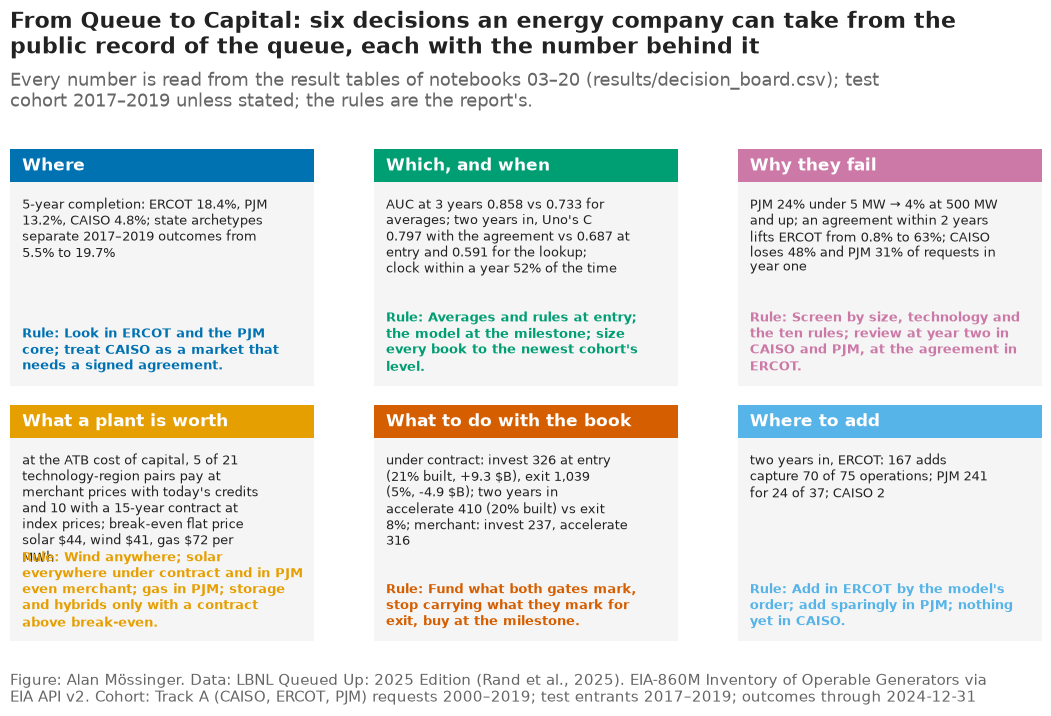

In [6]:
import textwrap

HEADERS = ["Where", "Which, and when", "Why they fail", "What a plant is worth", "What to do with the book", "Where to add"]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.2))
tile_colours = ["#0072B2", "#009E73", "#CC79A7", "#E69F00", "#D55E00", "#56B4E9"]
for ax, (_, row), colour, header in zip(axes.ravel(), board.iterrows(), tile_colours, HEADERS):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="#F5F5F5", edgecolor="none"))
    ax.add_patch(plt.Rectangle((0, 0.86), 1, 0.14, transform=ax.transAxes, facecolor=colour, edgecolor="none"))
    ax.text(0.04, 0.93, header, transform=ax.transAxes, fontsize=12.5, fontweight="bold", color="white", va="center")
    ax.text(0.04, 0.80, "\n".join(textwrap.wrap(row["numbers"].replace("$", "\$"), 36)), transform=ax.transAxes, fontsize=9.2, va="top", color=plots.INK, linespacing=1.25)
    ax.text(0.04, 0.05, "\n".join(textwrap.wrap("Rule: " + row["rule"], 36)), transform=ax.transAxes, fontsize=9.2, va="bottom", color=colour, fontweight="bold", linespacing=1.25)
plots.finish(fig, "From Queue to Capital: six decisions an energy company can take from the public record of the queue, each with the number behind it",
             "Every number is read from the result tables of notebooks 03–20 (results/decision_board.csv); test cohort 2017–2019 unless stated; the rules are the report's.",
             "Track A (CAISO, ERCOT, PJM) requests 2000–2019; test entrants 2017–2019; outcomes through 2024-12-31", eia=True)
dsave(fig, "D0_decision_board", "The decision board: the six decisions of the report, each with its headline numbers and its rule, read from the result tables.")
plt.show()

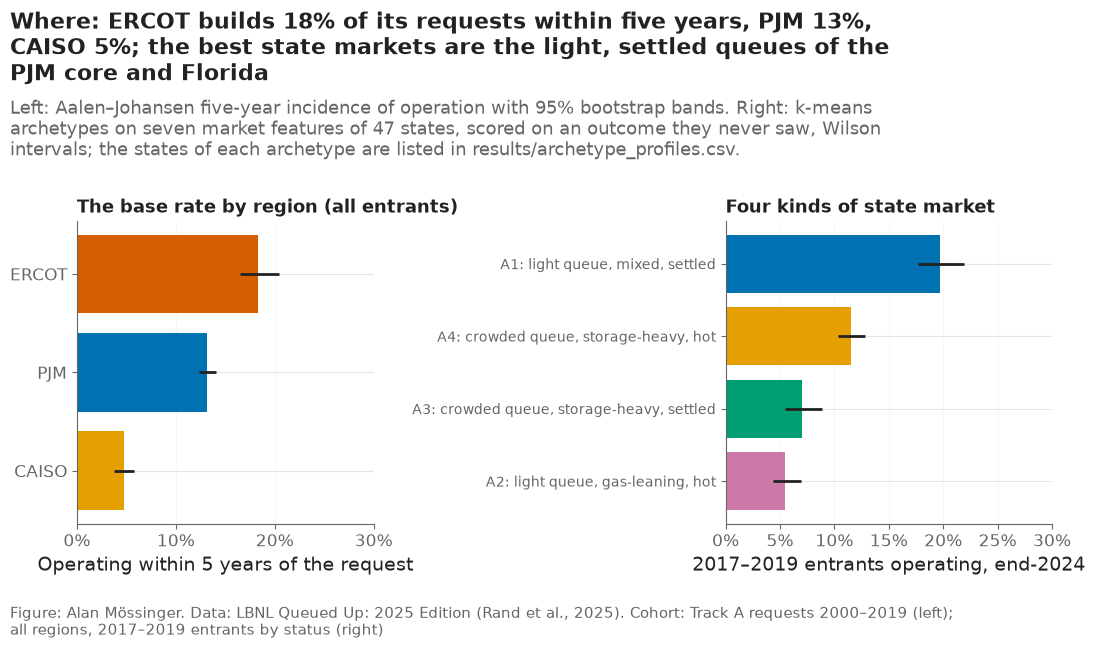

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
y = np.arange(3)
vals = reg5.loc[REGIONS]
ax.barh(y, vals["cif_operation"], color=[RC[r] for r in REGIONS])
ax.hlines(y, vals["cif_operation_low"], vals["cif_operation_high"], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels(REGIONS); ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlim(0, 0.3)
ax.set_xlabel("Operating within 5 years of the request")
ax.set_title("The base rate by region (all entrants)", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
ax = axes[1]
y = np.arange(len(arch))
ax.barh(y, arch["completion_2017_2019"], color=["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"][:len(arch)])
ax.hlines(y, arch["low"], arch["high"], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels([f"A{int(a) + 1}: {n}" for a, n in zip(arch["archetype"], arch["name"])], fontsize=10)  # numbered as in F25
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlim(0, 0.3)
ax.set_xlabel("2017–2019 entrants operating, end-2024")
ax.set_title("Four kinds of state market", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"Where: ERCOT builds {reg5.loc['ERCOT', 'cif_operation']:.0%} of its requests within five years, PJM {reg5.loc['PJM', 'cif_operation']:.0%}, CAISO {reg5.loc['CAISO', 'cif_operation']:.0%}; the best state markets are the light, settled queues of the PJM core and Florida",
             "Left: Aalen–Johansen five-year incidence of operation with 95% bootstrap bands. Right: k-means archetypes on seven market features of 47 states, scored on an outcome they never saw, Wilson intervals; the states of each archetype are listed in results/archetype_profiles.csv.",
             "Track A requests 2000–2019 (left); all regions, 2017–2019 entrants by status (right)")
dsave(fig, "D1_where", "Decision 1, where: five-year completion by region and the four state archetypes with the share of 2017–2019 entrants operating by end-2024.")
plt.show()

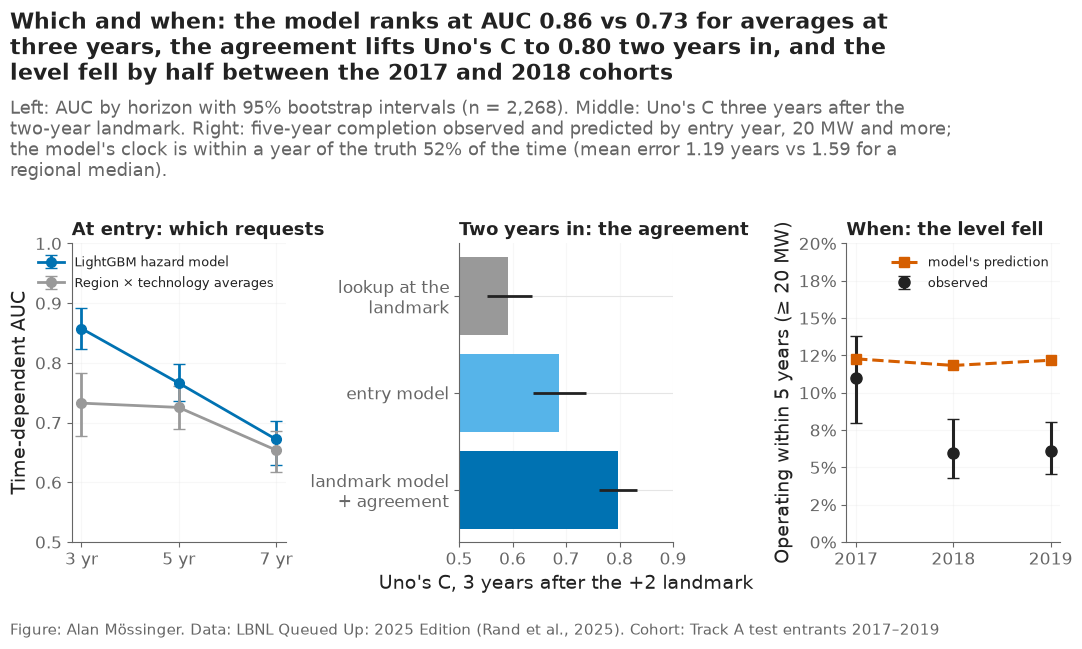

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
ax = axes[0]
for model, colour, label in [("dt_lgbm", "#0072B2", "LightGBM hazard model"), ("baseline", "#999999", "Region × technology averages")]:
    part = met[(met["model"] == model) & (met["metric"] == "auc")].sort_values("horizon")
    ax.errorbar(part["horizon"], part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt="-o", color=colour, lw=2, capsize=4, label=label)
ax.set_xticks([3, 5, 7]); ax.set_xticklabels(["3 yr", "5 yr", "7 yr"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Time-dependent AUC")
ax.set_title("At entry: which requests", fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=9.5, loc="upper right")
ax.grid(alpha=0.3)
ax = axes[1]
order = ["fair baseline", "entry model", "agreement updated"]
labels = ["lookup at the\nlandmark", "entry model", "landmark model\n+ agreement"]
y = np.arange(3)
ax.barh(y, [lm2.loc[m, "estimate"] for m in order], color=["#999999", "#56B4E9", "#0072B2"])
ax.hlines(y, [lm2.loc[m, "low"] for m in order], [lm2.loc[m, "high"] for m in order], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("Uno's C, 3 years after the +2 landmark")
ax.set_title("Two years in: the agreement", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
ax = axes[2]
ax.errorbar(big["entry_year"], big["observed"], yerr=[big["observed"] - big["low"], big["high"] - big["observed"]], fmt="o", color=plots.INK, capsize=4, ms=8, label="observed")
ax.plot(big["entry_year"], big["v2"], "s--", color="#D55E00", ms=7, label="model's prediction")
ax.set_xticks(big["entry_year"])
ax.set_ylim(0, 0.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Operating within 5 years (≥ 20 MW)")
ax.set_title("When: the level fell", fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=9.5)
ax.grid(alpha=0.3)
t_mae = timing.loc[("all", "dt_lgbm"), "mae_years"]; b_mae = timing.loc[("all", "training median by region"), "mae_years"]
plots.finish(fig, f"Which and when: the model ranks at AUC {auc3['dt_lgbm']:.2f} vs {auc3['baseline']:.2f} for averages at three years, the agreement lifts Uno's C to {uno2['agreement updated']:.2f} two years in, and the level fell by half between the 2017 and 2018 cohorts",
             f"Left: AUC by horizon with 95% bootstrap intervals (n = 2,268). Middle: Uno's C three years after the two-year landmark. Right: five-year completion observed and predicted by entry year, 20 MW and more; the model's clock is within a year of the truth {timing.loc[('all', 'dt_lgbm'), 'share_within_1_year']:.0%} of the time (mean error {t_mae:.2f} years vs {b_mae:.2f} for a regional median).",
             "Track A test entrants 2017–2019")
dsave(fig, "D2_which_and_when", "Decision 2, which and when: ranking at entry against averages, the landmark gain from the agreement, and the fall of the level across entry cohorts.")
plt.show()

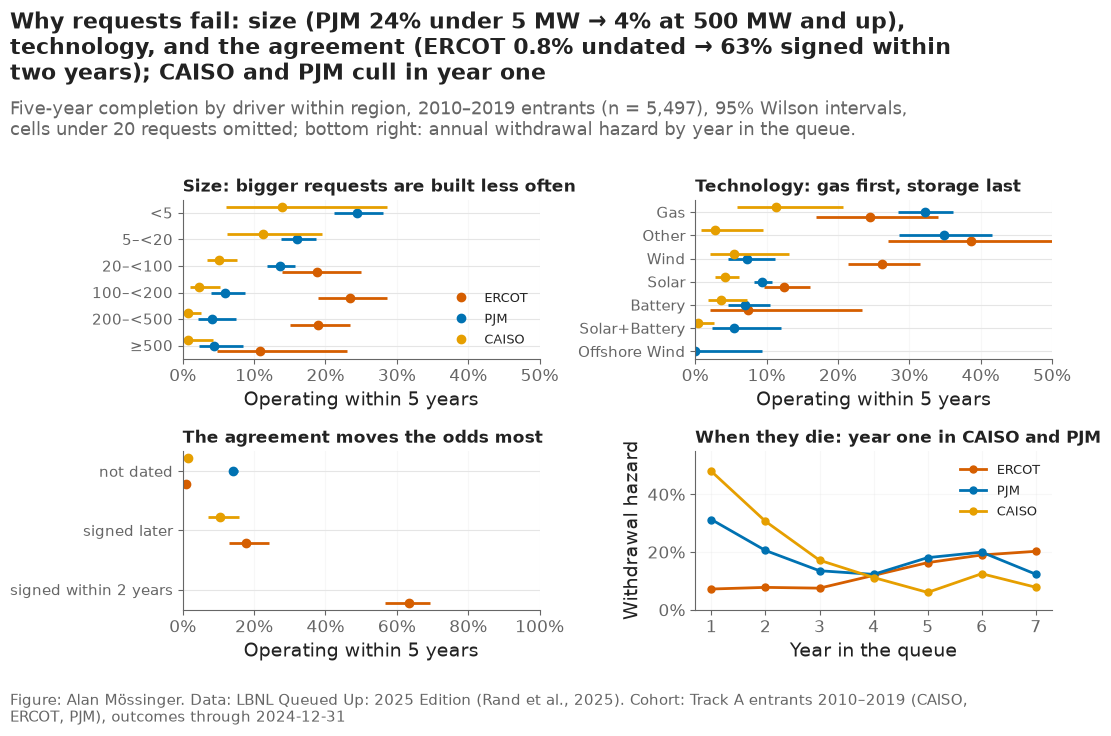

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
offsets = {"ERCOT": 0.22, "PJM": 0.0, "CAISO": -0.22}


def driver_panel(ax, driver, levels, title, xmax):
    sub = drv[(drv["driver"] == driver) & ~drv["thin"]]
    for region in REGIONS:
        r = sub[sub["region"] == region].set_index("level").reindex(levels)
        y = np.arange(len(levels)) + offsets[region]
        ax.hlines(y, r["low"], r["high"], color=RC[region], lw=2)
        ax.plot(r["rate"], y, "o", color=RC[region], ms=6, label=region)
    ax.set_yticks(np.arange(len(levels))); ax.set_yticklabels(levels, fontsize=10.5); ax.invert_yaxis()
    ax.set_xlim(0, xmax); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Operating within 5 years"); ax.set_title(title, fontsize=12.5, loc="left"); ax.grid(axis="x", alpha=0.3)


driver_panel(axes[0, 0], "Size at entry (MW)", config.SIZE_LABELS, "Size: bigger requests are built less often", 0.5)
driver_panel(axes[0, 1], "Technology", ["Gas", "Other", "Wind", "Solar", "Battery", "Solar+Battery", "Offshore Wind"], "Technology: gas first, storage last", 0.5)
driver_panel(axes[1, 0], "Agreement (2025 file)", ["not dated", "signed later", "signed within 2 years"], "The agreement moves the odds most", 1.0)
axes[0, 0].legend(frameon=False, fontsize=9.5, loc="lower right")
ax = axes[1, 1]
for region in REGIONS:
    h = hz[hz["region"] == region]
    ax.plot(h["year_in_queue"], h["h_withdrawal"], "-o", color=RC[region], lw=2, ms=5, label=f"{region}")
ax.set_ylim(0, 0.55); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Year in the queue"); ax.set_ylabel("Withdrawal hazard")
ax.set_title("When they die: year one in CAISO and PJM", fontsize=12.5, loc="left")
ax.legend(frameon=False, fontsize=9.5); ax.grid(alpha=0.3)
plots.finish(fig, f"Why requests fail: size (PJM {size_pjm_small:.0%} under 5 MW → {size_pjm_big:.0%} at 500 MW and up), technology, and the agreement (ERCOT {ia_ercot_none:.1%} undated → {ia_ercot_in2:.0%} signed within two years); CAISO and PJM cull in year one",
             "Five-year completion by driver within region, 2010–2019 entrants (n = 5,497), 95% Wilson intervals, cells under 20 requests omitted; bottom right: annual withdrawal hazard by year in the queue.",
             "Track A entrants 2010–2019 (CAISO, ERCOT, PJM), outcomes through 2024-12-31")
dsave(fig, "D3_why", "Decision 3, why requests fail: five-year completion by size, technology and the executed agreement within each region, and the annual withdrawal hazard by year in the queue.")
plt.show()

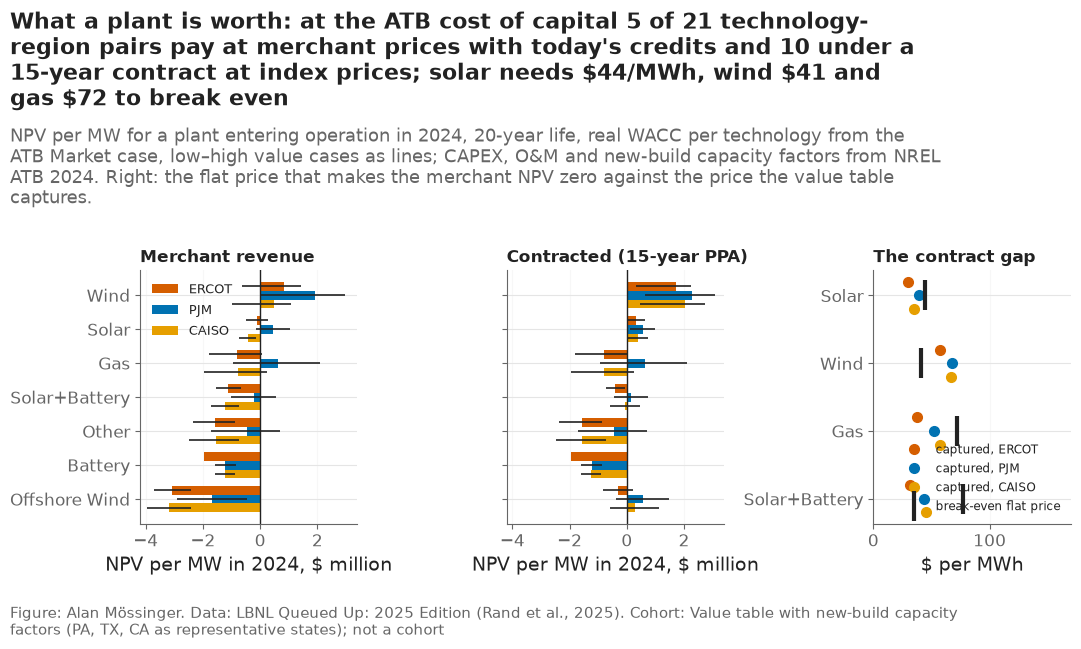

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
order = ["Wind", "Solar", "Gas", "Solar+Battery", "Other", "Battery", "Offshore Wind"]
width = 0.26
at = n24.set_index(["tech", "region"])
for ax, col, title in [(axes[0], "npv_per_mw", "Merchant revenue"), (axes[1], "npv_contracted", "Contracted (15-year PPA)")]:
    y = np.arange(len(order))
    for k, region in enumerate(REGIONS):
        part = at.xs(region, level="region").reindex(order)
        yy = y + (k - 1) * width
        ax.barh(yy, part[f"{col}_base"] / 1e6, height=width, color=RC[region], label=region)
        ax.hlines(yy, part[f"{col}_low"] / 1e6, part[f"{col}_high"] / 1e6, color=plots.INK, lw=1.2)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_yticks(y); ax.set_yticklabels(order if ax is axes[0] else [""] * len(order)); ax.invert_yaxis()
    ax.set_xlim(-4.2, 3.4)
    ax.set_xlabel("NPV per MW in 2024, \\$ million")
    ax.set_title(title, fontsize=12.5, loc="left")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(frameon=False, fontsize=9.5, loc="upper left")
ax = axes[2]
techs = ["Solar", "Wind", "Gas", "Solar+Battery"]
y = np.arange(len(techs))
for k, region in enumerate(REGIONS):
    cap = [at.loc[(t, region), "captured_price_base"] for t in techs]
    ax.plot(cap, y + (k - 1) * 0.2, "o", color=RC[region], ms=7, label=f"captured, {region}")
ax.plot([at.loc[(t, "PJM"), "breakeven_price_base"] for t in techs], y, "|", color=plots.INK, ms=22, mew=3, label="break-even flat price")
ax.set_yticks(y); ax.set_yticklabels(techs); ax.invert_yaxis()
ax.set_xlim(0, 170); ax.set_xlabel("\\$ per MWh")
ax.set_title("The contract gap", fontsize=12.5, loc="left")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"What a plant is worth: at the ATB cost of capital {positive24} of 21 technology-region pairs pay at merchant prices with today's credits and {positive24c} under a 15-year contract at index prices; solar needs \\${be['Solar']:.0f}/MWh, wind \\${be['Wind']:.0f} and gas \\${be['Gas']:.0f} to break even",
             "NPV per MW for a plant entering operation in 2024, 20-year life, real WACC per technology from the ATB Market case, low–high value cases as lines; CAPEX, O&M and new-build capacity factors from NREL ATB 2024. Right: the flat price that makes the merchant NPV zero against the price the value table captures.",
             "Value table with new-build capacity factors (PA, TX, CA as representative states); not a cohort")
dsave(fig, "D4_worth", "Decision 4, what a plant is worth: NPV per MW by technology and region at a 2024 operation date under merchant and contracted revenue, and the break-even flat price against the captured energy price.")
plt.show()

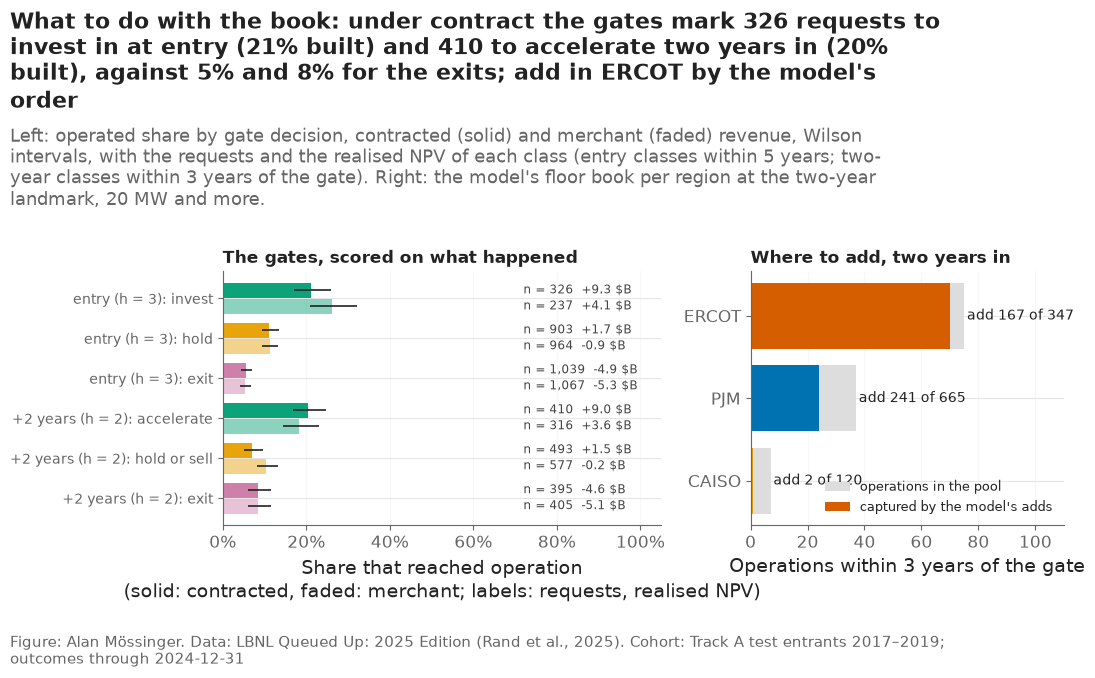

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
rows = [("G1 entry", "invest"), ("G1 entry", "hold"), ("G1 entry", "exit"), ("G2 two years", "accelerate"), ("G2 two years", "hold or sell"), ("G2 two years", "exit")]
palette = {"invest": "#009E73", "accelerate": "#009E73", "hold": "#E69F00", "hold or sell": "#E69F00", "exit": "#CC79A7"}
y = np.arange(len(rows))
for rc, dy, alpha, marker in [("contracted", -0.2, 0.95, "o"), ("merchant", 0.2, 0.45, "s")]:
    sel = pd.concat([gate_tab[(g, rc)].loc[[d_]] for g, d_ in rows])
    ax.barh(y + dy, sel["operated_share"], height=0.38, color=[palette[d_] for _, d_ in rows], alpha=alpha, label=f"{rc} revenue")
    ax.hlines(y + dy, sel["low"], sel["high"], color=plots.INK, lw=1.2)
    for yy, (_, r) in zip(y + dy, sel.iterrows()):
        ax.text(0.72, yy, f"n = {int(r['n']):,}  {r['realised_npv_$M'] / 1e3:+.1f} \\$B", va="center", fontsize=8.5, color="#444444")
ax.set_yticks(y); ax.set_yticklabels([f"{'entry (h = 3)' if g == 'G1 entry' else '+2 years (h = 2)'}: {d_}" for g, d_ in rows], fontsize=10); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share that reached operation" + chr(10) + "(solid: contracted, faded: merchant; labels: requests, realised NPV)"); ax.set_title("The gates, scored on what happened", fontsize=12.5, loc="left"); ax.grid(axis="x", alpha=0.3)
ax = axes[1]
y = np.arange(3)
ax.barh(y, bm.loc[REGIONS, "pool_operations"], color="#DDDDDD", label="operations in the pool")
ax.barh(y, bm.loc[REGIONS, "realised_operations"], color=[RC[r] for r in REGIONS], label="captured by the model's adds")
for yy, r in zip(y, REGIONS):
    ax.text(bm.loc[r, "pool_operations"] + 1, yy, f"add {int(bm.loc[r, 'requests_added'])} of {int(bm.loc[r, 'pool_requests'])}", va="center", fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(REGIONS); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.set_xlabel("Operations within 3 years of the gate")
ax.set_title("Where to add, two years in", fontsize=12.5, loc="left"); ax.legend(frameon=False, fontsize=9, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"What to do with the book: under contract the gates mark {int(g1.loc['invest', 'n'])} requests to invest in at entry ({g1.loc['invest', 'operated_share']:.0%} built) and {int(g2.loc['accelerate', 'n'])} to accelerate two years in ({g2.loc['accelerate', 'operated_share']:.0%} built), against {g1.loc['exit', 'operated_share']:.0%} and {g2.loc['exit', 'operated_share']:.0%} for the exits; add in ERCOT by the model's order",
             "Left: operated share by gate decision, contracted (solid) and merchant (faded) revenue, Wilson intervals, with the requests and the realised NPV of each class (entry classes within 5 years; two-year classes within 3 years of the gate). Right: the model's floor book per region at the two-year landmark, 20 MW and more.",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
dsave(fig, "D5_book", "Decision 5, the book: the gate classes scored on what happened under contracted and merchant revenue, and the model's floor book per region two years in.")
plt.show()

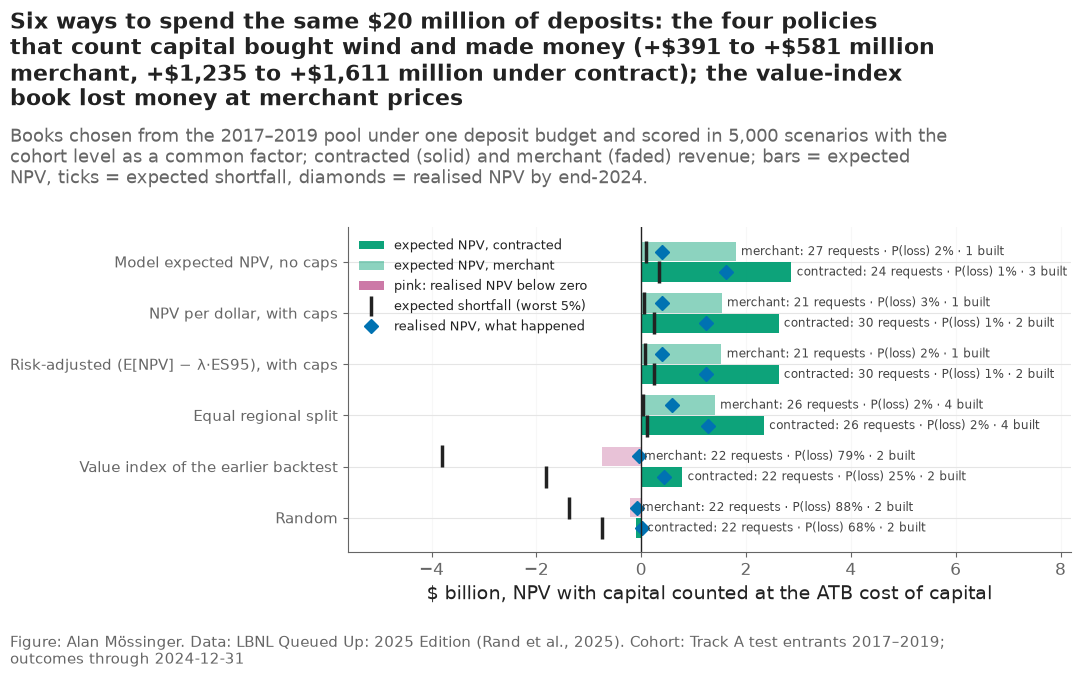

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.8))
short = {"equal regional split": "Equal regional split", "NPV per dollar, with caps": "NPV per dollar, with caps", "model expected NPV, no caps": "Model expected NPV, no caps",
         "risk-adjusted (E[NPV] − λ·ES95), with caps": "Risk-adjusted (E[NPV] − λ·ES95), with caps", "fair baseline, value index (section 5)": "Value index of the earlier backtest", "random (section 5)": "Random"}
p = pol.copy()
p["label"] = p["policy"].map(short)
order_pol = p[p["revenue_case"] == "contracted"].sort_values("expected_npv_$M")["label"].tolist()
y = np.arange(len(order_pol))
for rc, dy, alpha in [("contracted", -0.2, 0.95), ("merchant", 0.2, 0.45)]:
    q = p[p["revenue_case"] == rc].set_index("label").loc[order_pol]
    colours = ["#009E73" if v > 0 else "#CC79A7" for v in q["realised_npv_$M"]]
    ax.barh(y + dy, q["expected_npv_$M"] / 1e3, height=0.38, color=colours, alpha=alpha, label=f"expected NPV, {rc}")
    ax.plot(q["es95_$M"] / 1e3, y + dy, "|", color=plots.INK, ms=16, mew=2.5, label="expected shortfall (worst 5%)" if rc == "contracted" else None)
    ax.plot(q["realised_npv_$M"] / 1e3, y + dy, "D", color="#0072B2", ms=7, label="realised NPV, what happened" if rc == "contracted" else None)
    for yy, (_, r) in zip(y + dy, q.iterrows()):
        ax.text(max(r["expected_npv_$M"], r["realised_npv_$M"]) / 1e3 + 0.1, yy, f"{rc}: {int(r['requests'])} requests · P(loss) {r['p_negative_npv']:.0%} · {int(r['realised_operations_5yr'])} built", va="center", fontsize=8.5, color="#444444")
ax.axvline(0, color=plots.INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels(order_pol, fontsize=10.5)
ax.set_xlim(-5.6, 8.2)  # room for the labels on the right; the legend sits in the empty space left of zero on the top rows
ax.set_xlabel("\\$ billion, NPV with capital counted at the ATB cost of capital")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#009E73", alpha=0.95, label="expected NPV, contracted"), Patch(color="#009E73", alpha=0.45, label="expected NPV, merchant"), Patch(color="#CC79A7", label="pink: realised NPV below zero"),
                   Line2D([], [], color=plots.INK, marker="|", ms=14, mew=2.5, ls="none", label="expected shortfall (worst 5%)"), Line2D([], [], color="#0072B2", marker="D", ms=7, ls="none", label="realised NPV, what happened")],
          frameon=False, fontsize=9, loc="upper left")
ax.grid(axis="x", alpha=0.3)
NPV_POLICIES = ["Equal regional split", "NPV per dollar, with caps", "Model expected NPV, no caps", "Risk-adjusted (E[NPV] − λ·ES95), with caps"]
pc = p[(p["revenue_case"] == "contracted") & p["label"].isin(NPV_POLICIES)]
pm = p[(p["revenue_case"] == "merchant") & p["label"].isin(NPV_POLICIES)]
old_book = p[(p["revenue_case"] == "contracted") & (p["label"] == "Value index of the earlier backtest")]["realised_npv_$M"].iloc[0]
plots.finish(fig, f"Six ways to spend the same \${BUDGET_M:.0f} million of deposits: the four policies that count capital bought wind and made money (+\${pm['realised_npv_$M'].min():,.0f} to +\${pm['realised_npv_$M'].max():,.0f} million merchant, +\${pc['realised_npv_$M'].min():,.0f} to +\${pc['realised_npv_$M'].max():,.0f} million under contract); the value-index book lost money at merchant prices",
             "Books chosen from the 2017–2019 pool under one deposit budget and scored in 5,000 scenarios with the cohort level as a common factor; contracted (solid) and merchant (faded) revenue; bars = expected NPV, ticks = expected shortfall, diamonds = realised NPV by end-2024.",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
dsave(fig, "D6_policies", "Decision 5, continued: six allocation policies under the same deposit budget, contracted and merchant revenue: expected NPV, expected shortfall and realised NPV.")
plt.show()

**Reading this.** The seven images carry the report's decisions one per page: D0 the board, D1 where (ERCOT and the PJM core; CAISO only with an agreement), D2 which and when (the model at AUC 0.86 against 0.73 at entry, the agreement two years in, the level that fell by half), D3 why (size, technology, the agreement; year one in CAISO and PJM, after year four in ERCOT), D4 worth (five of 21 pairs positive at merchant prices; break-even solar $57, wind $51, gas $80 per MWh) D5 the book (the gate classes, where to add) and D6 the six ways to spend the same budget. Every number on them is read from a result table in this run, so they change when the results change.

## 5. Checks

In [13]:
checks = pd.DataFrame([
    {"check": "decision board: seven images saved as PNG and SVG", "value": 14,
     "pass": all((paths.FIGURES / f"{n}.{ext}").exists() for n in ["D0_decision_board", "D1_where", "D2_which_and_when", "D3_why", "D4_worth", "D5_book", "D6_policies"] for ext in ["png", "svg"])},
    {"check": "every registered criterion is scored on each of its horizons", "value": f"{len(scored)} lines scored for {len(criteria)} registered rows",
     "pass": len(scored) == sum(len(str(h).split(", ")) if cid not in ("C8", "C9", "C10", "C11", "C12") else {"C8": 2, "C9": 1, "C10": 1, "C11": 1, "C12": 1}[cid]
                                for cid, h in zip(criteria["id"], criteria["horizons"]))},
    {"check": "no registered line dropped", "value": sorted(scored["id"].unique()), "pass": set(scored["id"]) == set(criteria["id"])},
    {"check": "the v1 verdict file is untouched (8 of 12)", "value": int((v1["result"] == "PASS").sum()), "pass": int((v1["result"] == "PASS").sum()) == 8 and len(v1) == 12},
])
checks.to_csv(R / "evaluate_v2_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,decision board: seven images saved as PNG and SVG,14,True
1,every registered criterion is scored on each of its horizons,12 lines scored for 8 registered rows,True
2,no registered line dropped,"[C10, C11, C12, C6, C7, C8, C9]",True
3,the v1 verdict file is untouched (8 of 12),8,True


## Takeaways

- 3 of 12 pre-registered v2 lines pass: the landmark gain at +24 months (C8), the simulated band's coverage (C11) and the leakage guard (C12).
- At entry, for utility-scale requests, the model and the fair baseline are indistinguishable (C6 0 of 4); the level stays too high after repair (C7 0 of 2); the registered backtest is a tie (C9, C10).
- The v1 verdict (8 of 12) is untouched and reported beside the v2 one; the difference is the benchmark and the question, not the model.
- Track B's calibrated LightGBM tracks the observed share built across its bins (figure 18_02).
- **What goes to the report:** the scored table and figure 18_01; the two-verdict summary; the sentence that the value of the model is at the milestones, not at entry.